In [12]:
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

# La base du DWH, créée par 04_ETL/etl_pipeline.py
# Le notebook est dans 07_EDA, donc on remonte d'un dossier
con = sqlite3.connect("../04_ETL/project_11_dwh.db")

# Les tables MART disponibles
pd.read_sql_query("SELECT name FROM sqlite_master WHERE name LIKE 'mart_%' ORDER BY name", con)

,name
0,mart_incident_rate_shift_role
1,mart_incidents_by_area
2,mart_incidents_month
3,mart_kpi_summary
4,mart_near_miss
5,mart_recurring_incident_type
6,mart_severity_distribution


In [13]:
kpi = pd.read_sql_query("SELECT * FROM mart_kpi_summary", con)
kpi

,kpi_id,kpi,libelle,valeur,unite
0,KPI1,Incidents/month,Moyenne mensuelle des incidents sur les mois c...,144.00,incidents/mois
1,KPI2,Severity distribution,Part des incidents graves (gravité HIGH ou CRI...,22.30,%
2,KPI3,Incidents by area,Score de risque de la zone la plus à risque : ...,95.40,score /100
3,KPI4,Near-miss count,Presque-accidents : incidents NEAR_MISS + obse...,759.00,near-miss
4,KPI5,Recurring incident type,Part du type d'incident le plus fréquent : SPI...,18.10,%
5,KPI6,Incident rate by shift/role,Incidents par travailleur du groupe le plus to...,4.84,incidents/travailleur
6,KPI7,Unsafe observations,Part des observations de terrain classées UNSAFE,29.40,%
7,KPI8,Total incidents,Nombre d'incidents chargés dans le DWH (contrô...,1400.00,incidents


## Graphique 1 : tendance mensuelle des incidents
*Question HSE : la situation s'améliore-t-elle ou se dégrade-t-elle ?*

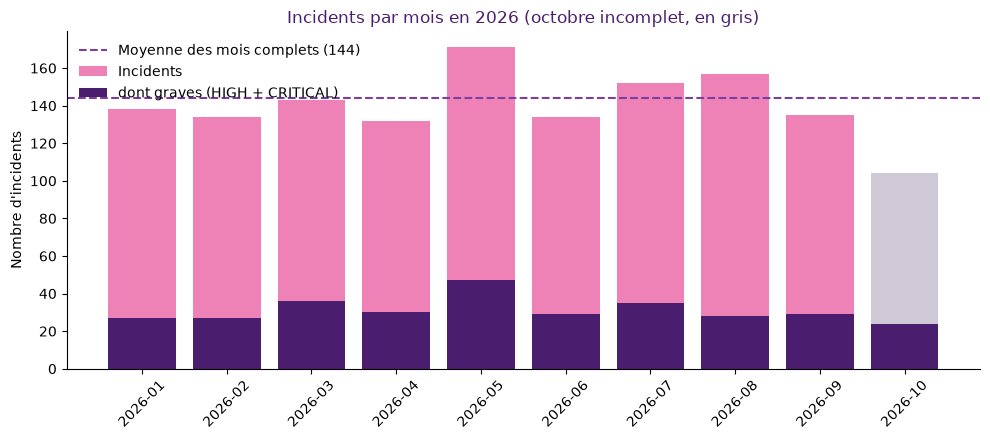

,mois,nb_incidents,nb_graves,pct_graves,mois_complet
0,2026-01,138,27,19.6,1
1,2026-02,134,27,20.1,1
2,2026-03,143,36,25.2,1
3,2026-04,132,30,22.7,1
4,2026-05,171,47,27.5,1
5,2026-06,134,29,21.6,1
6,2026-07,152,35,23.0,1
7,2026-08,157,28,17.8,1
8,2026-09,135,29,21.5,1
9,2026-10,104,24,23.1,0


In [16]:
import os
os.makedirs("figures", exist_ok=True)

# Couleurs de la charte (les mêmes que le dashboard)
VIOLET_FONCE = "#4A1D6E"
VIOLET = "#7B3FA0"
ROSE = "#EE82B7"
GRIS_INCOMPLET = "#CFC8D6"

mois = pd.read_sql_query("SELECT * FROM mart_incidents_month ORDER BY mois", con)

# Moyenne calculée sur les mois complets seulement (octobre exclu)
moyenne = mois[mois["mois_complet"] == 1]["nb_incidents"].mean()

# Octobre (incomplet) en gris, les autres mois en rose
couleurs = [ROSE if complet == 1 else GRIS_INCOMPLET for complet in mois["mois_complet"]]

plt.figure(figsize=(10, 4.5))
plt.bar(mois["mois"], mois["nb_incidents"], color=couleurs, label="Incidents")
plt.bar(mois["mois"], mois["nb_graves"], color=VIOLET_FONCE, label="dont graves (HIGH + CRITICAL)")
plt.axhline(moyenne, color=VIOLET, linestyle="--", label=f"Moyenne des mois complets ({moyenne:.0f})")
plt.title("Incidents par mois en 2026 (octobre incomplet, en gris)", color=VIOLET_FONCE)
plt.ylabel("Nombre d'incidents")
plt.xticks(rotation=45)
plt.legend(frameon=False)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/01_tendance_mensuelle.png", dpi=150)
plt.show()

mois[["mois", "nb_incidents", "nb_graves", "pct_graves", "mois_complet"]]

**Interprétation.** Le volume est stable, entre 132 et 157 incidents par mois (moyenne de 144 sur les mois complets), sans tendance nette. **Mai est le pic : 171 incidents**, soit +29,5 % par rapport à avril, avec la plus forte part de graves (27,5 %). Octobre (104) paraît bas, mais il s'arrête au 28 : on ne peut pas conclure à une amélioration.
**Action HSE :** chercher en priorité la cause du pic de mai (activité, saison, effectif).

## Graphique 2 : répartition des incidents par gravité
*Question HSE : quelle part des incidents est vraiment grave ?*

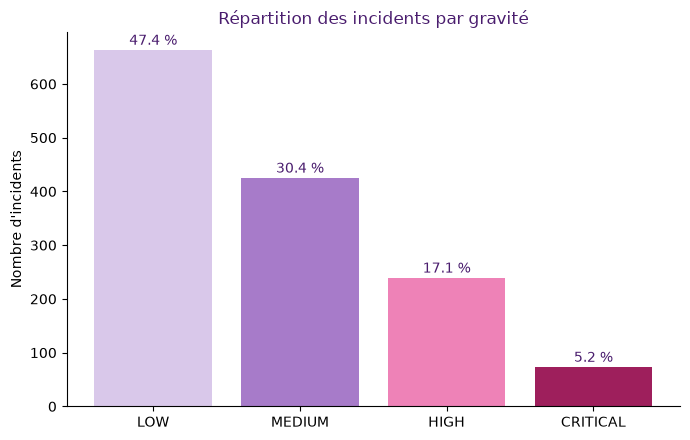

,severity,nb_incidents,pct
0,LOW,663,47.4
1,MEDIUM,425,30.4
2,HIGH,239,17.1
3,CRITICAL,73,5.2


In [17]:
gravite = pd.read_sql_query("SELECT * FROM mart_severity_distribution", con)

# Ordre naturel de la gravité, du plus faible au plus grave
ordre = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]
gravite = gravite.set_index("severity").loc[ordre].reset_index()

# Couleurs de la charte : du lavande (faible) à la framboise (critique)
couleurs = ["#D9C8EA", "#A77BC9", "#EE82B7", "#9E1F5C"]

plt.figure(figsize=(7, 4.5))
plt.bar(gravite["severity"], gravite["nb_incidents"], color=couleurs)

# Écrire le pourcentage au-dessus de chaque barre
for i, ligne in gravite.iterrows():
    plt.text(i, ligne["nb_incidents"] + 10, f"{ligne['pct']} %", ha="center", color=VIOLET_FONCE)

plt.title("Répartition des incidents par gravité", color=VIOLET_FONCE)
plt.ylabel("Nombre d'incidents")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/02_gravite.png", dpi=150)
plt.show()

gravite

**Interprétation.** Près de la moitié des incidents sont faibles (LOW : 663, soit 47,4 %). Mais **22,3 % sont graves** : HIGH (239) + CRITICAL (73) = 312 incidents, plus d'un sur cinq. Les 73 incidents critiques représentent environ 7 par mois.
**Action HSE :** fixer un objectif de réduction de la part d'incidents graves, suivi chaque mois.

## Graphique 3 : les zones les plus à risque
*Question HSE : où concentrer les inspections et les rondes de sécurité ?*

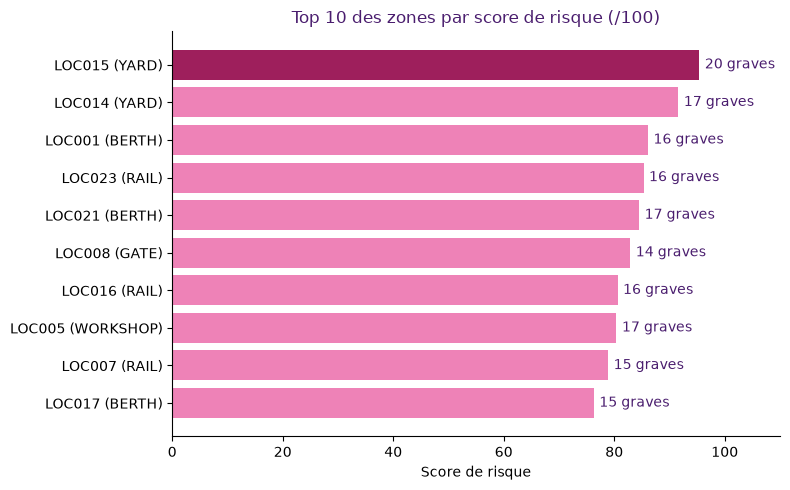

,location_id,area_type,nb_incidents,nb_graves,pct_unsafe,score_risque
0,LOC015,YARD,66,20,28.1,95.4
1,LOC014,YARD,64,17,36.5,91.6
2,LOC001,BERTH,59,16,35.3,86.1
3,LOC023,RAIL,60,16,32.8,85.3
4,LOC021,BERTH,61,17,26.1,84.5
5,LOC008,GATE,64,14,34.3,82.9
6,LOC016,RAIL,55,16,28.5,80.6
7,LOC005,WORKSHOP,56,17,22.8,80.4
8,LOC007,RAIL,55,15,30.0,78.9
9,LOC017,BERTH,54,15,26.1,76.3


In [18]:
zones = pd.read_sql_query(
    "SELECT * FROM mart_incidents_by_area ORDER BY score_risque DESC LIMIT 10", con
)

# Pour barh, la première ligne est dessinée en bas : on inverse pour avoir la plus risquée en haut
zones = zones.sort_values("score_risque")
etiquettes = zones["location_id"] + " (" + zones["area_type"] + ")"

# La zone la plus risquée (dernière ligne après le tri) en framboise, les autres en rose
couleurs = [ROSE] * (len(zones) - 1) + ["#9E1F5C"]

plt.figure(figsize=(8, 5))
plt.barh(etiquettes, zones["score_risque"], color=couleurs)

# Écrire le nombre d'incidents graves à droite de chaque barre
for i, (score, graves) in enumerate(zip(zones["score_risque"], zones["nb_graves"])):
    plt.text(score + 1, i, f"{graves} graves", va="center", color=VIOLET_FONCE)

plt.title("Top 10 des zones par score de risque (/100)", color=VIOLET_FONCE)
plt.xlabel("Score de risque")
plt.xlim(0, 110)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/03_zones_risque.png", dpi=150)
plt.show()

zones.sort_values("score_risque", ascending=False)[["location_id", "area_type", "nb_incidents", "nb_graves", "pct_unsafe", "score_risque"]]

**Interprétation.** Le score de risque combine 50 % incidents graves, 30 % nombre d'incidents et 20 % part d'observations UNSAFE. Les deux zones les plus à risque sont des **parcs à conteneurs** : **LOC015 (95,4, 20 graves)** et **LOC014 (91,6, 17 graves)**. Le parc est aussi le type de zone avec la plus forte part d'incidents graves (28 %). Suivent un quai (LOC001), le rail (LOC023) et un autre quai (LOC021).
**Action HSE :** renforcer en priorité les rondes sur le parc à conteneurs, à commencer par LOC015 et LOC014.

## Graphique 4 : exposition par rôle et par équipe
*Question HSE : quels groupes de travailleurs former en priorité ?*

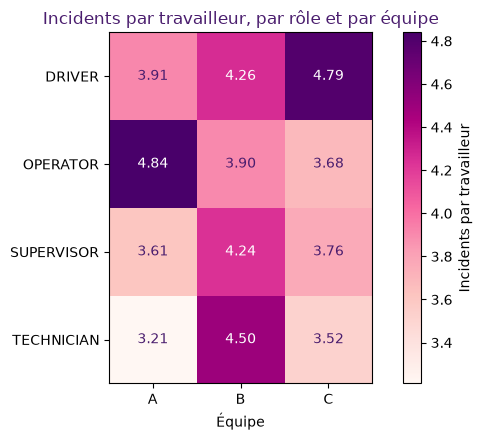

,role,shift,nb_travailleurs,nb_incidents,incidents_par_travailleur
0,OPERATOR,A,25,121,4.84
1,DRIVER,C,29,139,4.79
2,TECHNICIAN,B,32,144,4.50


In [19]:
taux = pd.read_sql_query("SELECT * FROM mart_incident_rate_shift_role", con)

# Tableau croisé : une ligne par rôle, une colonne par équipe
tableau = taux.pivot(index="role", columns="shift", values="incidents_par_travailleur")

plt.figure(figsize=(6.5, 4.5))
plt.imshow(tableau.values, cmap="RdPu")
plt.colorbar(label="Incidents par travailleur")

plt.xticks(range(len(tableau.columns)), tableau.columns)
plt.yticks(range(len(tableau.index)), tableau.index)

# Écrire la valeur au centre de chaque case : en blanc sur les cases foncées, en violet foncé sinon
moyenne_cases = tableau.values.mean()
for ligne in range(tableau.shape[0]):
    for colonne in range(tableau.shape[1]):
        valeur = tableau.values[ligne, colonne]
        couleur_texte = "white" if valeur > moyenne_cases else VIOLET_FONCE
        plt.text(colonne, ligne, f"{valeur:.2f}", ha="center", va="center", color=couleur_texte)

plt.title("Incidents par travailleur, par rôle et par équipe", color=VIOLET_FONCE)
plt.xlabel("Équipe")
plt.tight_layout()
plt.savefig("figures/04_heatmap_role_equipe.png", dpi=150)
plt.show()

taux.sort_values("incidents_par_travailleur", ascending=False).head(3)

**Interprétation.** Le groupe le plus exposé est **OPERATOR de l'équipe A : 4,84 incidents par travailleur** (121 incidents pour 25 travailleurs), suivi de DRIVER équipe C (4,79) et TECHNICIAN équipe B (4,50). Le moins exposé est TECHNICIAN équipe A (3,21). L'écart reste modéré et les groupes sont petits (21 à 41 personnes) : c'est un signal à vérifier.
**Limite :** sans heures travaillées, c'est un taux par effectif et non par exposition réelle.
**Action HSE :** briefing sécurité renforcé pour les opérateurs de l'équipe A et les conducteurs de l'équipe C.

## Graphique 5 : near-miss et incidents graves
*Question HSE : les presque-accidents annoncent-ils les accidents graves ?*

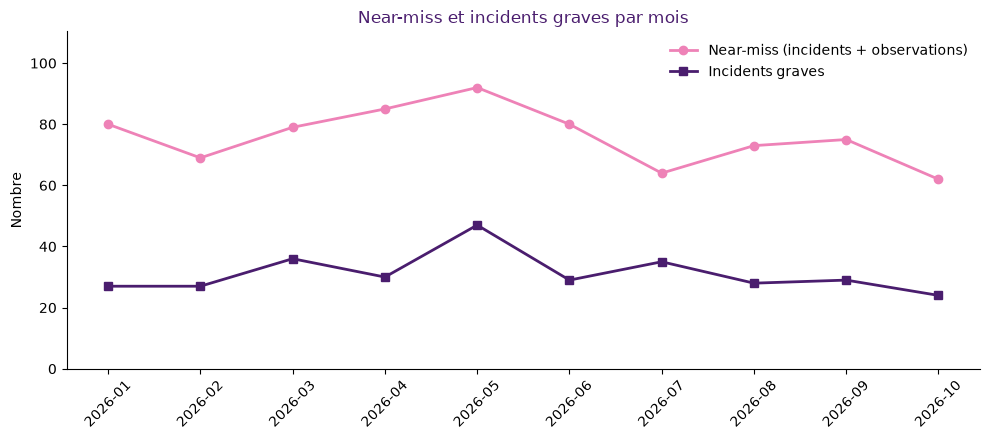

In [20]:
nm = pd.read_sql_query("SELECT * FROM mart_near_miss ORDER BY mois", con)

# Combien de near-miss pour un incident grave, chaque mois
nm["ratio"] = (nm["near_miss_total"] / nm["incidents_graves"]).round(2)

plt.figure(figsize=(10, 4.5))
plt.plot(nm["mois"], nm["near_miss_total"], marker="o", linewidth=2, color=ROSE, label="Near-miss (incidents + observations)")
plt.plot(nm["mois"], nm["incidents_graves"], marker="s", linewidth=2, color=VIOLET_FONCE, label="Incidents graves")
plt.title("Near-miss et incidents graves par mois", color=VIOLET_FONCE)
plt.ylabel("Nombre")
plt.ylim(0, nm["near_miss_total"].max() * 1.2)
plt.xticks(rotation=45)
plt.legend(frameon=False)
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()

**Interprétation.** On compte environ **2,4 near-miss par incident grave** (759 pour 312). Les near-miss restent assez stables (62 à 92 par mois), alors que les incidents graves varient davantage (24 à 47). Le ratio est le plus bas en **juillet (1,83)** et en **mai (1,96)**, le mois du pic d'incidents graves : plus d'accidents graves, ou moins de signalements. La corrélation (+0,59, sur 10 mois seulement) reflète surtout le volume d'activité, pas un lien de cause.
**Action HSE :** encourager la déclaration des near-miss et suivre ce ratio chaque mois ; une chute est un signal d'alerte.

## Graphique 6 : observations UNSAFE et incidents graves, par zone
*Question HSE : les observations de terrain suffisent-elles à repérer les zones dangereuses ?*

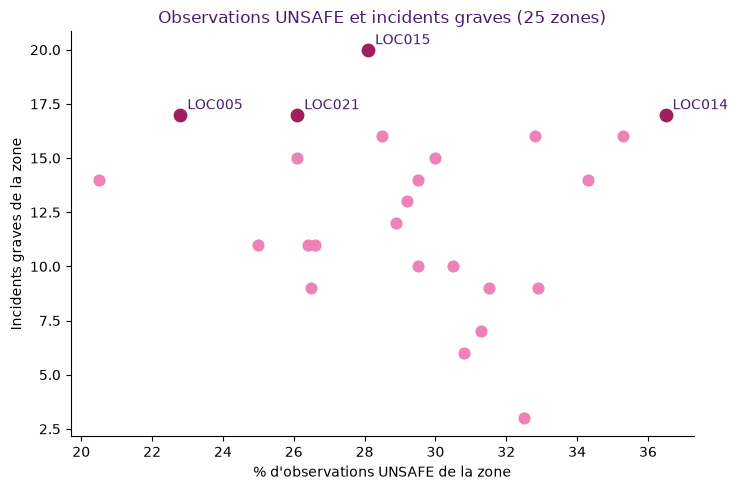

Corrélation % UNSAFE / incidents graves : -0.14


In [21]:
zones_toutes = pd.read_sql_query("SELECT * FROM mart_incidents_by_area", con)

# Les 4 zones avec le plus d'incidents graves, mises en évidence en framboise
top4 = zones_toutes.nlargest(4, "nb_graves")

plt.figure(figsize=(7.5, 5))
plt.scatter(zones_toutes["pct_unsafe"], zones_toutes["nb_graves"], s=60, color=ROSE)
plt.scatter(top4["pct_unsafe"], top4["nb_graves"], s=80, color="#9E1F5C")

# Nommer les 4 zones qui ont le plus d'incidents graves
for _, zone in top4.iterrows():
    plt.annotate(zone["location_id"], (zone["pct_unsafe"], zone["nb_graves"]),
                 xytext=(5, 4), textcoords="offset points", color=VIOLET_FONCE)

plt.title("Observations UNSAFE et incidents graves (25 zones)", color=VIOLET_FONCE)
plt.xlabel("% d'observations UNSAFE de la zone")
plt.ylabel("Incidents graves de la zone")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/06_unsafe_vs_graves.png", dpi=150)
plt.show()

print("Corrélation % UNSAFE / incidents graves :",
      round(zones_toutes["pct_unsafe"].corr(zones_toutes["nb_graves"]), 2))

**Interprétation.** Les points ne forment pas de diagonale : la corrélation est **faible et légèrement négative (environ -0,14)**. LOC015, la zone la plus touchée (20 incidents graves), n'a que 28,1 % d'observations UNSAFE, alors que LOC006 en a 32,5 % pour seulement 3 incidents graves. Les observations seules ne prédisent donc pas les zones dangereuses : il faut les croiser avec l'historique des incidents, ce que fait le score de risque (graphique 3).
**Action HSE :** ne pas piloter la prévention sur les seules observations, et vérifier que toutes les zones sont observées de façon équilibrée.

## Conclusion

| Question HSE | Réponse | Graphique |
|---|---|---|
| Quand ? | Environ 144 incidents par mois complet, pic en mai (171) ; octobre incomplet | 1 |
| Quelle gravité ? | 22,3 % d'incidents graves, dont 73 critiques | 2 |
| Où ? | Le parc à conteneurs en priorité : LOC015 (95,4) et LOC014 (91,6) | 3 |
| Qui ? | Opérateurs de l'équipe A (4,84 incidents par travailleur), écart modéré | 4 |
| Signaux faibles ? | 2,4 near-miss par incident grave ; ratio en baisse en mai et juillet | 5 |

Les observations UNSAFE seules ne prédisent pas les zones dangereuses (corrélation -0,14, graphique 6) : il faut les croiser avec l'historique des incidents, comme le fait le score de risque.

**Limites :** pas d'heures travaillées (taux par effectif, pas par exposition) ; équipe du travailleur et non de l'heure de l'incident ; octobre incomplet, exclu des moyennes ; données synthétiques et petits effectifs ; `home_area` des engins non rattachable aux zones (alerte DQ11).

In [10]:
con.close()